# 03 · Feature engineering and training

**Goal.** Turn each expense into numbers (features), train three models on the **training split only**,
tune their settings with 5-fold cross-validation, and save the best one for the app.
The test split is not touched here: it is kept for an honest final check in notebook 04.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
import seaborn as sns

# One quiet style for every chart: light grid, no top/right frame, grey text.
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "grid.color": "#ebeae6", "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12,
    "figure.dpi": 110})

import numpy as np
import pandas as pd
from sklearn.model_selection import cross_validate

from src import config, data, train as T
from src.features import INPUT_COLUMNS, clean_text, embedding_features, numeric_features, tfidf_features

household = data.load_source("household")
train, test = data.time_split(household)
print(f"Training rows: {len(train)} ({train.date.min():%Y-%m-%d} to {train.date.max():%Y-%m-%d})")

[map] household: dropped 444 of 2176 rows with no matching category
[clean] removed 159 empty-description rows and 0 exact duplicates
Training rows: 1258 (2015-01-01 to 2018-03-15)


## Step 3 · The features

| Feature | Type | Why it might help |
|---|---|---|
| TF-IDF of cleaned description (words + 2-word phrases, `min_df=2`) | sparse text, one column per word/phrase | Exact words like "milk", "auto", "recharge" are strong clues. TF-IDF gives rare, specific words more weight than common ones. |
| MiniLM embedding of cleaned description | 384 dense numbers | Captures *meaning*, so "cab" and "taxi" look alike even if "cab" never appeared in training. |
| `log1p(amount)` | number | Categories cost different amounts (EDA: median Transport 40 INR vs Shopping 300 INR). The log squashes the long tail. |
| `weekday` (0 = Mon … 6 = Sun) | number | Spending habits differ by day. |
| `is_weekend` | 0/1 flag | EDA: Transport is 24% of weekend rows vs 17% on weekdays. |

The two models compare **TF-IDF vs MiniLM** for the text; both get the same three numeric features.
Everything is wrapped in a scikit-learn `ColumnTransformer` inside a `Pipeline`, so the app runs
exactly the same steps as training.

In [2]:
examples = train.sample(6, random_state=config.RANDOM_SEED)
pd.DataFrame({"raw description": examples.description, "clean_text()": examples.description.map(clean_text)})

,raw description,clean_text()
561,Dadar West to siddhivinayak,dadar west to siddhivinayak
101,local - Place 0 to Place 5 return,local place to place return
51,grocery,grocery
63,dinner treat,dinner treat
1073,Toothbrush (buy 2 get 1),toothbrush buy get
424,Mobile Service Provider recharge wfh,mobile service provider recharge wfh


In [3]:
X_train = train[INPUT_COLUMNS]
tfidf_matrix = tfidf_features().fit_transform(X_train)
embedding_matrix = embedding_features().fit_transform(X_train)
print(f"TF-IDF features:    {tfidf_matrix.shape[1]} columns ({tfidf_matrix.shape[1] - 3} words/phrases + 3 numeric)")
print(f"Embedding features: {embedding_matrix.shape[1]} columns (384 MiniLM + 3 numeric)")
pd.DataFrame(numeric_features(examples), columns=["log1p_amount", "weekday", "is_weekend"],
             index=examples.description).round(2)

TF-IDF features:    722 columns (719 words/phrases + 3 numeric)
Embedding features: 387 columns (384 MiniLM + 3 numeric)


,log1p_amount,weekday,is_weekend
description,,,
Dadar West to siddhivinayak,3.43,4.0,0.0
local - Place 0 to Place 5 return,3.43,0.0,0.0
grocery,4.80,2.0,0.0
dinner treat,6.91,4.0,0.0
Toothbrush (buy 2 get 1),4.62,6.0,1.0
Mobile Service Provider recharge wfh,5.71,4.0,0.0


## Step 4 · Training

1. **Majority baseline**: always predicts the most common category. The floor.
2. **TF-IDF + numeric → Logistic Regression**
3. **MiniLM + numeric → Logistic Regression**

For models 2 and 3 we try `C` ∈ {0.1, 1, 10} (smaller C = simpler model, more regularisation) and
`class_weight` ∈ {None, "balanced"} ("balanced" makes mistakes on rare categories cost more).
Each of the 6 combinations is scored by **5-fold cross-validation**: the training data is cut into 5 parts,
the model is trained on 4 and scored on the 5th, five times over. The score is macro-F1.

In [4]:
baseline_cv = cross_validate(T.make_baseline(), X_train, train.category, cv=T.cv_splitter(),
                             scoring={"macro_f1": "f1_macro", "accuracy": "accuracy"})
searches = {name: T.tune(name, train) for name in T.FEATURE_SETS}

rows = [{"model": "majority_baseline", "C": "-", "class_weight": "-",
         "cv_macro_f1": baseline_cv["test_macro_f1"].mean(), "cv_macro_f1_std": baseline_cv["test_macro_f1"].std(),
         "cv_accuracy": baseline_cv["test_accuracy"].mean()}]
for name, search in searches.items():
    best = search.best_index_
    rows.append({"model": name, "C": search.best_params_["clf__C"],
                 "class_weight": str(search.best_params_["clf__class_weight"]),
                 "cv_macro_f1": search.cv_results_["mean_test_macro_f1"][best],
                 "cv_macro_f1_std": search.cv_results_["std_test_macro_f1"][best],
                 "cv_accuracy": search.cv_results_["mean_test_accuracy"][best]})
results = pd.DataFrame(rows).set_index("model")
results.round(3)

,C,class_weight,cv_macro_f1,cv_macro_f1_std,cv_accuracy
model,,,,,
majority_baseline,-,-,0.056,0.000,0.292
tfidf_logreg,10,None,0.743,0.050,0.815
minilm_logreg,10,balanced,0.786,0.049,0.832


### Every setting tried

,C,class_weight,model,cv_macro_f1,cv_accuracy
0,0.1,None,tfidf_logreg,0.409,0.684
1,0.1,balanced,tfidf_logreg,0.588,0.656
2,1.0,None,tfidf_logreg,0.658,0.783
3,1.0,balanced,tfidf_logreg,0.700,0.789
4,10.0,None,tfidf_logreg,0.743,0.815
5,10.0,balanced,tfidf_logreg,0.697,0.794
0,0.1,None,minilm_logreg,0.441,0.708
1,0.1,balanced,minilm_logreg,0.665,0.724
2,1.0,None,minilm_logreg,0.727,0.818
3,1.0,balanced,minilm_logreg,0.772,0.821


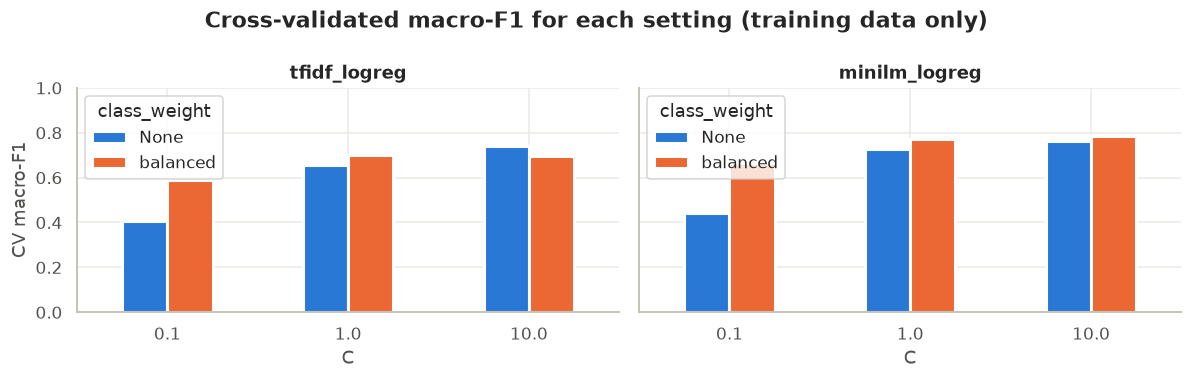

In [5]:
grid = pd.concat([
    pd.DataFrame(search.cv_results_["params"]).assign(
        model=name, cv_macro_f1=search.cv_results_["mean_test_macro_f1"],
        cv_accuracy=search.cv_results_["mean_test_accuracy"])
    for name, search in searches.items()]).rename(columns={"clf__C": "C", "clf__class_weight": "class_weight"})
grid["class_weight"] = grid["class_weight"].fillna("None")
display(grid.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (name, part) in zip(axes, grid.groupby("model", sort=False)):
    table = part.pivot(index="C", columns="class_weight", values="cv_macro_f1")
    table.plot.bar(ax=ax, color=["#2a78d6", "#eb6834"], edgecolor="white", linewidth=2)
    ax.set_title(name); ax.set_ylabel("CV macro-F1"); ax.tick_params(axis="x", rotation=0)
    ax.set_ylim(0, 1); ax.legend(title="class_weight")
fig.suptitle("Cross-validated macro-F1 for each setting (training data only)", fontweight="bold")
plt.tight_layout(); plt.show()

### Choose and save

The model with the highest **cross-validated** macro-F1 is chosen. We do not peek at the test split to choose.

In [6]:
chosen_name = results.drop(index="majority_baseline").cv_macro_f1.idxmax()
chosen = searches[chosen_name]
print(f"Chosen model: {chosen_name} with {chosen.best_params_}, CV macro-F1 {chosen.best_score_:.3f}")

metadata = T.build_metadata(chosen_name, chosen.best_params_, train, chosen.best_score_, version="v1")
T.save_model(chosen.best_estimator_, metadata)
print(f"Saved {T.MODEL_PATH.relative_to(config.ROOT)} and {T.METADATA_PATH.relative_to(config.ROOT)}")

# Notebook 04 compares all models on the test split, so keep the tuned runners-up too.
import joblib
baseline = T.make_baseline().fit(X_train, train.category)
candidates = {"majority_baseline": baseline} | {name: s.best_estimator_ for name, s in searches.items()}
joblib.dump(candidates, T.CANDIDATES_PATH)
print(f"Saved {T.CANDIDATES_PATH.relative_to(config.ROOT)} with {list(candidates)}")
metadata

Chosen model: minilm_logreg with {'clf__C': 10, 'clf__class_weight': 'balanced'}, CV macro-F1 0.786
Saved models/model.joblib and models/metadata.json
Saved models/candidates.joblib with ['majority_baseline', 'tfidf_logreg', 'minilm_logreg']


{'model_name': 'minilm_logreg',
 'model_version': 'v1',
 'features': ['minilm_embedding(clean description, 384 dims)',
  'log1p_amount',
  'weekday',
  'is_weekend'],
 'settings': {'C': 10, 'class_weight': 'balanced'},
 'train_date_range': ['2015-01-01', '2018-03-15'],
 'train_rows': 1258,
 'label_distribution': {'Food': 367,
  'Groceries': 347,
  'Transport': 252,
  'Shopping': 104,
  'Bills': 51,
  'Health': 74,
  'Education': 20,
  'Entertainment': 43},
 'cv_macro_f1': 0.7858,
 'default_amount': 60.0,
 'sklearn_version': '1.9.1',
 'saved_at': '2026-11-23T21:48:27'}

## What I learned